# Streaming decision tree demo: Palmer Penguins

This notebook demonstrates the `numcompute_stream` pipeline on the Palmer Penguins dataset. We predict **species** from four body measurements, evaluate each chunk **before** training on it, and plot the results.

Run the notebook from the `demo/` folder after installing the project (`pip install -e ".[dev]"`).

In [1]:
from pathlib import Path

import numpy as np

from numcompute.io import iter_csv_chunks, load_csv, read_header, split_columns
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import SimpleImputer, StandardScaler
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.visualise import (
    compare_models,
    plot_metric_over_time,
    plot_predictions_vs_ground_truth,
)

csv_paths = [
    Path("../data/penguins.csv"),
    Path("data/penguins.csv"),
    Path("penguins.csv"),
    Path("../penguins.csv"),
]
CSV = next((str(path) for path in csv_paths if path.is_file()), None)
if CSV is None:
    raise FileNotFoundError("Could not find penguins.csv in demo/ or data/.")

Path("figures").mkdir(exist_ok=True)
print("Reading:", CSV)

Reading: data/penguins.csv


## 1. Load the data

The input contains numeric measurements and text labels. Missing measurements are converted to `NaN` and handled by the streaming imputer.

In [2]:
header = read_header(CSV)
table = load_csv(CSV, skip_header=1, dtype=str)

NUMERIC = [2, 3, 4, 5]  # Bill length/depth, flipper length, body mass
X, _ = split_columns(table, NUMERIC, [])
y = table[:, 0]

print("Features:", [header[i] for i in NUMERIC])
print("Shape:", X.shape)
print("Species:", dict(zip(*np.unique(y, return_counts=True))))
print("Rows with missing measurements:", np.isnan(X).any(axis=1).sum())

Features: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
Shape: (344, 4)
Species: {np.str_('Adelie'): np.int64(152), np.str_('Chinstrap'): np.int64(68), np.str_('Gentoo'): np.int64(124)}
Rows with missing measurements: 2


## 2. Create a data stream

Shuffle the rows to mix the species, then process 20 samples at a time. We compare this with the original species-ordered file later.

In [3]:
CHUNK = 20


def chunk_iter(X, y, size=CHUNK):
    for start in range(0, len(y), size):
        yield X[start:start + size], y[start:start + size]


rng = np.random.default_rng(42)
order = rng.permutation(len(y))
X_stream, y_stream = X[order], y[order]
print("Chunks:", (len(y_stream) + CHUNK - 1) // CHUNK)

Chunks: 18


## 3. Train and evaluate by chunk

The pipeline updates an imputer and scaler and retrains its decision tree after buffering 60 samples. The first three chunks cannot be scored because the tree is not yet fitted.

In [4]:
def make_pipeline(buffer_size):
    return Pipeline([
        ("impute", SimpleImputer("mean")),
        ("scale", StandardScaler()),
        ("tree", DecisionTreeClassifier(
            max_depth=4, buffer_size=buffer_size, random_state=0
        )),
    ])


trainer = StreamTrainer(make_pipeline(60), window=60)
trainer.run(chunk_iter(X_stream, y_stream))

print("Scored chunks:", sum(r["scored"] for r in trainer.score_log))
print("Tree retrains:", trainer.fit_log[-1]["n_retrains"])

Scored chunks: 15
Tree retrains: 5


In [5]:
trainer.summary()

{'chunks_scored': 18,
 'chunks_fitted': 18,
 'samples_scored': 284,
 'cumulative_accuracy': 0.9366197183098591,
 'macro_f1': 0.9245954416763723,
 'total_fit_seconds': 0.01641141902655363,
 'memory_bytes': 4564}

## 4. Visualise the results

The plots show test-before-train accuracy and the NumPy array memory held by the model.

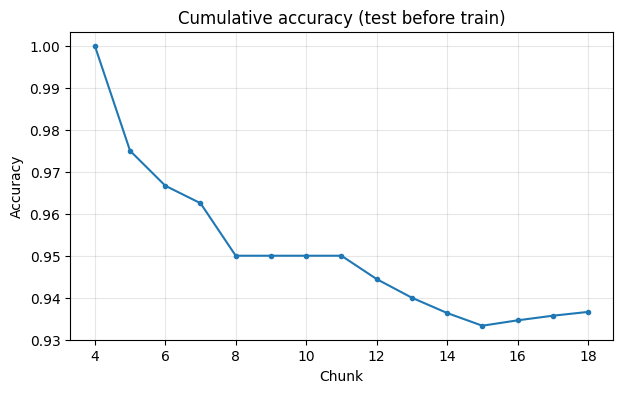

In [6]:
fig = plot_metric_over_time(
    trainer.history("cumulative_accuracy"),
    title="Cumulative accuracy (test before train)",
    ylabel="Accuracy",
    save_path="figures/cumulative_accuracy.png",
)

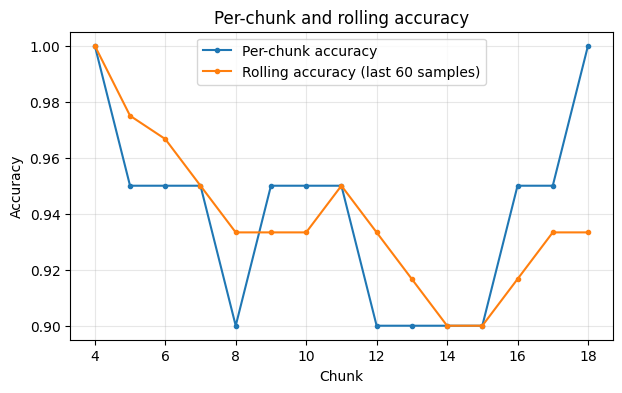

In [7]:
fig = compare_models(
    trainer.history("accuracy"),
    trainer.history("rolling_accuracy"),
    ["Per-chunk accuracy", "Rolling accuracy (last 60 samples)"],
    title="Per-chunk and rolling accuracy",
    ylabel="Accuracy",
)

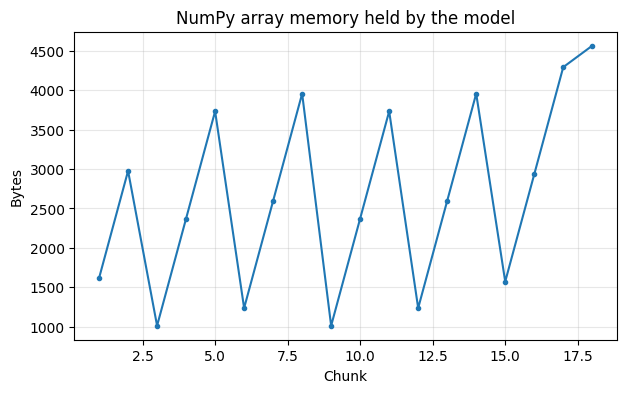

In [8]:
fig = plot_metric_over_time(
    trainer.history("memory_bytes"),
    title="NumPy array memory held by the model",
    ylabel="Bytes",
)

The memory plot counts NumPy array buffers reachable from the model, not the total RAM used by Python.

### Predictions from the final model

The next plot uses the model **after** processing the stream. It is separate from the test-before-train accuracy measurements.

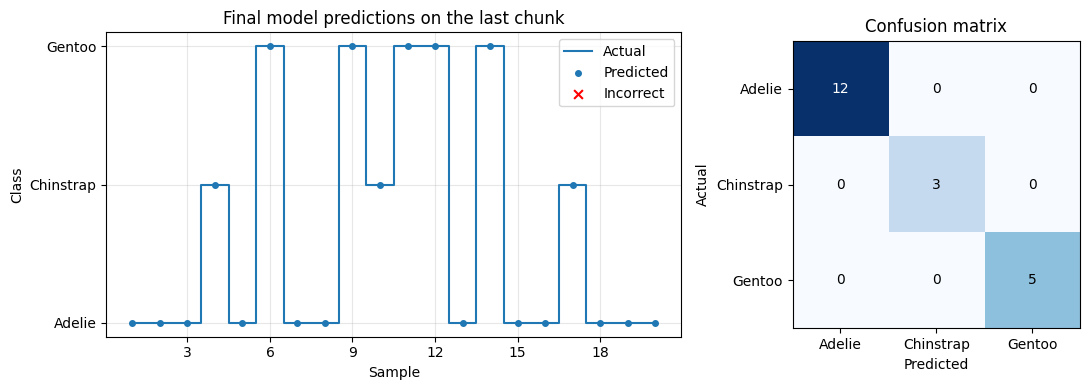

In [9]:
X_last, y_last = X_stream[-CHUNK:], y_stream[-CHUNK:]
fig = plot_predictions_vs_ground_truth(
    y_last,
    trainer.model.predict(X_last),
    title="Final model predictions on the last chunk",
    save_path="figures/latest_chunk_predictions.png",
)

## 5. Compare buffer sizes

Smaller buffers retrain more often. Because models become ready at different times, we report their overall prequential accuracy **and** accuracy on the same later chunks.

In [10]:
BUFFER_SIZES = (20, 60, 160)
runs = {60: trainer}
for size in (20, 160):
    runs[size] = StreamTrainer(make_pipeline(size), window=60).run(
        chunk_iter(X_stream, y_stream)
    )

# Start comparison when all models can make predictions.
shared_start = max(
    next(i for i, record in enumerate(t.score_log) if record["scored"])
    for t in runs.values()
)


def shared_accuracy_curve(t):
    records = t.score_log[shared_start:]
    counts = np.array([r["n_samples"] for r in records], dtype=float)
    correct = np.array([r["accuracy"] * r["n_samples"] for r in records])
    return np.cumsum(correct) / np.cumsum(counts)


shared_curves = {size: shared_accuracy_curve(t) for size, t in runs.items()}

print("Shared evaluation samples:", sum(
    r["n_samples"] for r in trainer.score_log[shared_start:]
))
print(f"{'buffer':>6} {'retrain':>7} {'scored':>7} "
      f"{'overall':>8} {'shared':>8} {'fit (s)':>9}")
for size in BUFFER_SIZES:
    t = runs[size]
    s = t.summary()
    print(f"{size:>6} {t.fit_log[-1]['n_retrains']:>7} "
          f"{s['samples_scored']:>7} {s['cumulative_accuracy']:>8.3f} "
          f"{shared_curves[size][-1]:>8.3f} "
          f"{s['total_fit_seconds']:>9.4f}")

Shared evaluation samples: 184
buffer retrain  scored  overall   shared   fit (s)
    20      17     324    0.870    0.859    0.0238
    60       5     284    0.937    0.929    0.0164
   160       2     184    0.946    0.946    0.0057


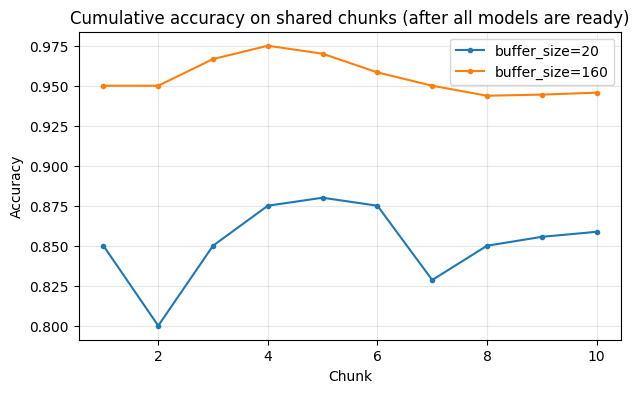

In [11]:
fig = compare_models(
    shared_curves[20],
    shared_curves[160],
    ["buffer_size=20", "buffer_size=160"],
    title="Cumulative accuracy on shared chunks (after all models are ready)",
    ylabel="Accuracy",
    save_path="figures/buffer_size_comparison.png",
)

## 6. Effect of data ordering

The original CSV groups rows by species. Reading it in file order creates a **class-distribution shift**, rather than a deliberate change in the relationship between measurements and species. The model may struggle when a new species first appears.

In [12]:
def ordered_chunks():
    for block in iter_csv_chunks(
        CSV, chunk_size=CHUNK, skip_header=1, dtype=str
    ):
        yield split_columns(block, NUMERIC, [])[0], block[:, 0]


ordered = StreamTrainer(make_pipeline(60), window=60).run(ordered_chunks())
shuffled = runs[60]
for name, t in (("shuffled", shuffled), ("file order", ordered)):
    print(f"{name:>10} accuracy: {t.summary()['cumulative_accuracy']:.3f}")

  shuffled accuracy: 0.937
file order accuracy: 0.792


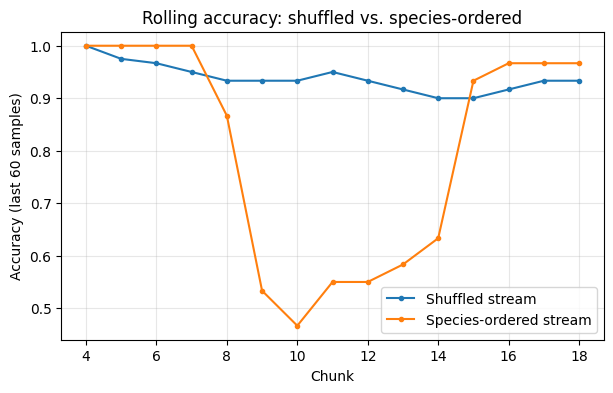

In [13]:
fig = compare_models(
    shuffled.history("rolling_accuracy"),
    ordered.history("rolling_accuracy"),
    ["Shuffled stream", "Species-ordered stream"],
    title="Rolling accuracy: shuffled vs. species-ordered",
    ylabel="Accuracy (last 60 samples)",
    save_path="figures/data_ordering_comparison.png",
)

## 7. Key observations

- **Streaming evaluation:** The tree cannot predict until its first buffer is fitted, so those initial chunks are excluded from accuracy calculations.
- **Buffer size:** Smaller buffers retrain more frequently (17, 5 and 2 retrains for buffer sizes 20, 60 and 160). On this shuffled stream, larger buffers achieved higher accuracy on the shared chunks (0.859, 0.929 and 0.946). Larger buffers use more training samples at each retraining, although the effect on accuracy may vary across datasets.
- **Data ordering:** Cumulative accuracy was 0.937 for the shuffled stream and 0.792 in file order. Grouping samples by species makes it harder to predict newly appearing classes: rolling accuracy drops while a new species first appears, then recovers once the tree has retrained on it. Retraining only on recent buffered data can also lose information about classes that no longer appear.
- **Memory:** The logged memory represents NumPy array buffers, not total process memory.